# softmax算子比较

In [1]:
import torch
import triton
import triton.language as tl
from triton.runtime import driver
from kernel.softmax_kernel import softmax as simple_softmax
from triton_examples.fused_softmax import softmax as official_softmax

In [2]:
temp = torch.randn(1024, 1024, device='cuda')
out_s = simple_softmax(temp)
out_o = official_softmax(temp)


In [3]:
temp = torch.randn(4096, 4096, device="cuda")

ms_simple = triton.testing.do_bench(
    lambda: simple_softmax(temp)
)

ms_official = triton.testing.do_bench(
    lambda: official_softmax(temp)
)

ms_torch = triton.testing.do_bench(
    lambda: torch.softmax(temp, dim=1)
)

print("simple  :", ms_simple, "ms")
print("official:", ms_official, "ms")
print("torch   :", ms_torch, "ms")

simple  : 0.6471439972519875 ms
official: 0.7505411431193352 ms
torch   : 0.7147268567766462 ms


In [4]:
@triton.testing.perf_report(
    triton.testing.Benchmark(
        x_names=["M"],
        x_vals=[128, 256, 512, 1024, 2048, 4096, 8192, 16384],
        line_arg="provider",
        line_vals=["simple", "official", "torch"],
        line_names=["Simple", "Official Persistent", "Torch"],
        styles=[
            ("blue", "-"),
            ("green", "-"),
            ("red", "-"),
        ],
        ylabel="GB/s",
        plot_name="softmax-m-scaling",
        args={"N": 4096},
    )
)
def benchmark(M, N, provider):
    x = torch.randn(M, N, device="cuda", dtype=torch.float32)

    if provider == "simple":
        ms = triton.testing.do_bench(
            lambda: simple_softmax(x)
        )

    elif provider == "official":
        ms = triton.testing.do_bench(
            lambda: official_softmax(x)
        )

    elif provider == "torch":
        ms = triton.testing.do_bench(
            lambda: torch.softmax(x, dim=1)
        )

    gbps = (
        2 * x.numel() * x.element_size()
        * 1e-9
        / (ms * 1e-3)
    )

    return gbps

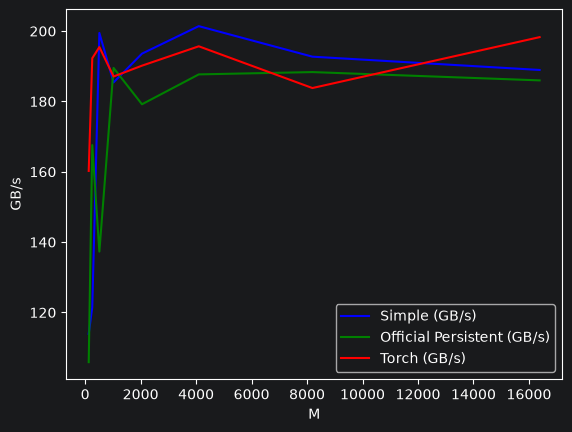

softmax-m-scaling:
         M  Simple (GB/s)  Official Persistent (GB/s)  Torch (GB/s)
0    128.0     113.919265                  105.869429    160.240315
1    256.0     121.443572                  167.584783    192.281664
2    512.0     199.468364                  137.302322    195.451368
3   1024.0     185.404363                  189.520524    187.085912
4   2048.0     193.582369                  179.190018    190.165108
5   4096.0     201.403799                  187.684798    195.675096
6   8192.0     192.724158                  188.343333    183.806768
7  16384.0     188.944528                  185.982691    198.277579


In [9]:
benchmark.run(
    show_plots=True,
    print_data=True,
)

Softmax 小结
- row-wise reduction：max + exp + sum + normalize
- fusion 通过减少中间 tensor 的 DRAM 往返获得主要收益
- simple one-row-per-program 与官方 persistent 在当前 4060 / N=4096 下性能接近
- persistent 是调度策略，不保证必然更快